# Practical 1 – 16 Qubit Random Number Generator

**Problem Statement:** Implementation of a 16 Qubit Random Number Generator.

**Objective:**
1. Understand creation of a qubit circuit
2. Create a 16 qubit Random Number Generator

**Outcome:** Displays a 16 qubit random number.

**Theory:** A qubit starts in state |0⟩. Applying a **Hadamard (H)** gate puts it in the equal superposition
(|0⟩ + |1⟩)/√2, so when it is measured it collapses to 0 or 1 with probability ½ each. This randomness comes
from quantum mechanics itself, not from an algorithm, so it is *truly* random (unlike classical pseudo-random generators).
Putting 16 qubits in superposition and measuring them gives a 16‑bit binary string, i.e. a random integer in the range **0 – 65535**.

In [1]:
# Run this cell first in Google Colab (installs Qiskit + simulator)
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jadha\AppData\Local\Temp\claude\efb368ed25e968d0\a89940ab-0696-4fca-91e1-025ecd80d2c1\scratchpad\qenv\Scripts\python.exe -m pip install --upgrade pip


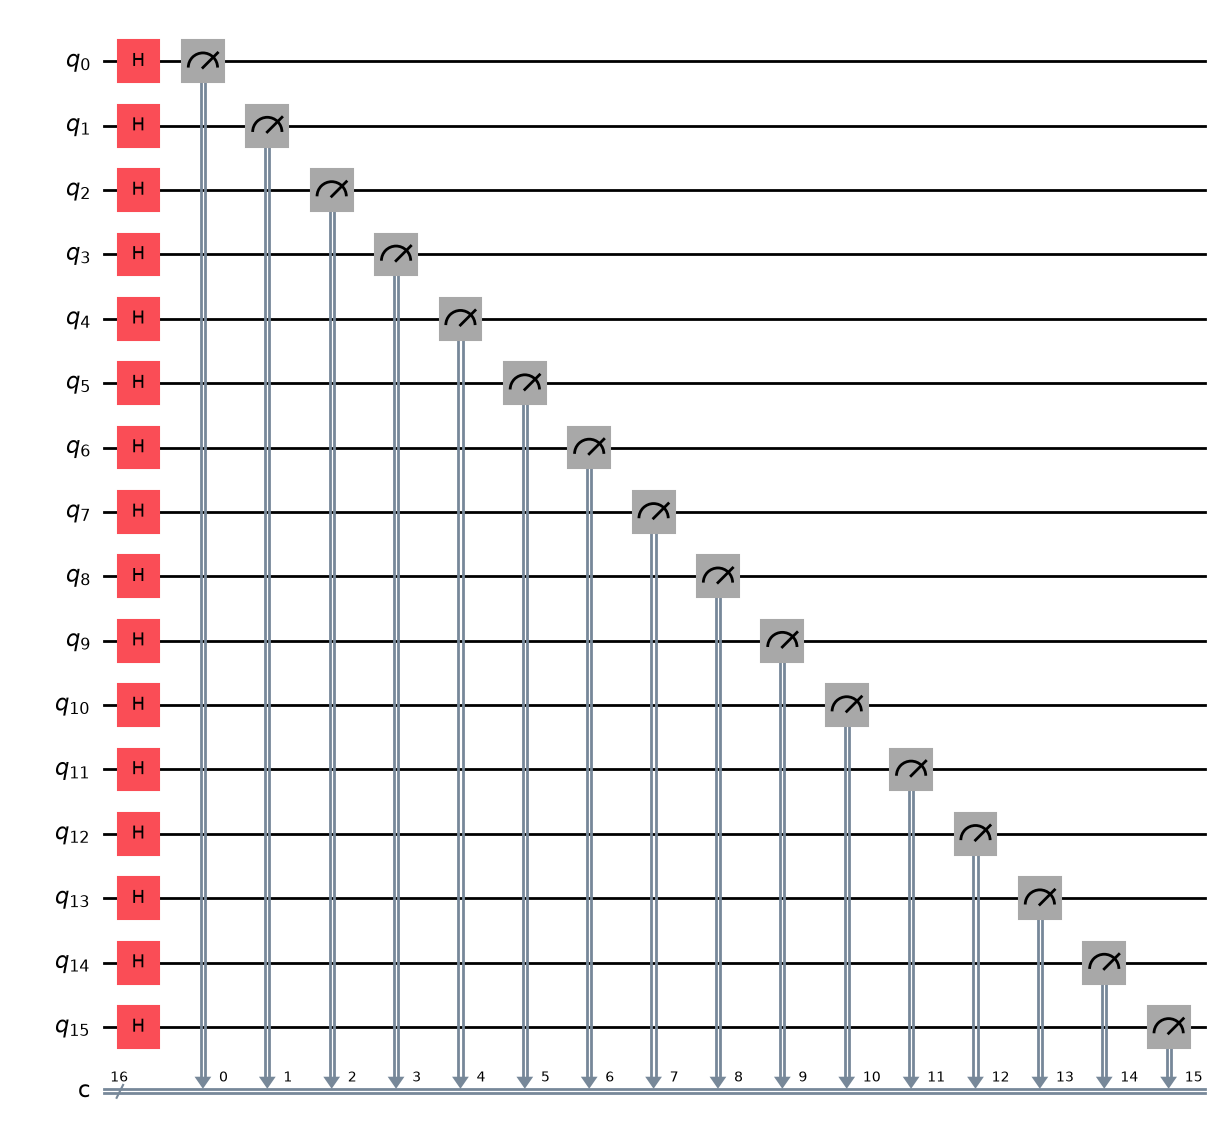

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

N_QUBITS = 16

# Step 1: create a circuit with 16 qubits and 16 classical bits
qc = QuantumCircuit(N_QUBITS, N_QUBITS)

# Step 2: put every qubit in superposition with a Hadamard gate
qc.h(range(N_QUBITS))

# Step 3: measure every qubit into its classical bit
qc.measure(range(N_QUBITS), range(N_QUBITS))

qc.draw('mpl', fold=-1)

In [3]:
simulator = AerSimulator()
compiled = transpile(qc, simulator)

def random_number_16bit():
    """Runs the circuit once (1 shot) and returns the measured 16-bit number."""
    result = simulator.run(compiled, shots=1, memory=True).result()
    bits = result.get_memory()[0]          # e.g. '1011001110001101'
    return bits, int(bits, 2)

bits, number = random_number_16bit()
print("Random 16-bit binary :", bits)
print("Random number (0-65535):", number)

Random 16-bit binary : 1101011100100111
Random number (0-65535): 55079


In [4]:
# Generate several random numbers
print("10 random numbers from the 16 qubit RNG:")
for i in range(10):
    bits, number = random_number_16bit()
    print(f"{i+1:2d}. {bits}  ->  {number}")

10 random numbers from the 16 qubit RNG:
 1. 0101010011111110  ->  21758
 2. 0101111001000000  ->  24128
 3. 0111101111010111  ->  31703
 4. 1011111010110101  ->  48821
 5. 1001101101010111  ->  39767
 6. 0010001100100001  ->  8993
 7. 0000001000011001  ->  537
 8. 0110000101010110  ->  24918
 9. 1001000100110000  ->  37168
10. 0111010010111111  ->  29887


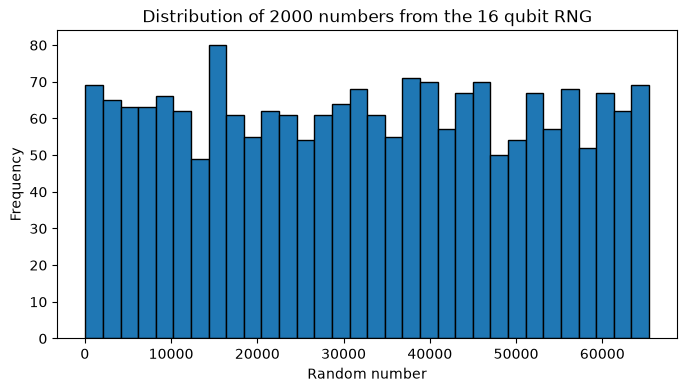

Min: 62  Max: 65408  Mean: 32621.662 (ideal mean = 32767.5)


In [5]:
# Check uniformity: generate 2000 numbers in one job and plot a histogram
result = simulator.run(compiled, shots=2000, memory=True).result()
numbers = [int(b, 2) for b in result.get_memory()]

plt.figure(figsize=(8, 4))
plt.hist(numbers, bins=32, edgecolor='black')
plt.title("Distribution of 2000 numbers from the 16 qubit RNG")
plt.xlabel("Random number"); plt.ylabel("Frequency")
plt.show()
print("Min:", min(numbers), " Max:", max(numbers), " Mean:", sum(numbers)/len(numbers), "(ideal mean = 32767.5)")

### (Optional) Run on a real IBM quantum computer
Get a free API token from <https://quantum.ibm.com>, then uncomment and run the cell below.

In [6]:
# %pip install -q qiskit-ibm-runtime
# from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
# service = QiskitRuntimeService(channel="ibm_quantum_platform", token="YOUR_API_TOKEN")
# backend = service.least_busy(operational=True, simulator=False)
# job = Sampler(backend).run([transpile(qc, backend)], shots=1)
# bits = list(job.result()[0].data.c.get_counts())[0]
# print("Random number from real quantum hardware:", int(bits, 2))

**Conclusion:** We created a 16 qubit circuit, used Hadamard gates to create superposition and measured the qubits to
obtain truly random 16-bit numbers (0 – 65535). The histogram shows the outputs are uniformly distributed.